In [51]:
import math
import numpy as np
import matplotlib.pyplot as g
import torch
import random
from graphviz import Digraph
%matplotlib inline

In [86]:
class Scalar:
        def __init__(self, value, label="", oprt = "", children = ()):
            self.value = value
            self.label = label
            self.oprt = oprt 
            self.children = children
            self.der = 0.0
            self._backward = lambda: None

        def __add__(self, other):

            other = other if isinstance(other, Scalar) else Scalar(other)
            out = Scalar(self.value + other.value, "", oprt="+", children=(self, other))
            
            def _backward():
                self.der = 1.0 * out.der
                other.der = 1.0 * out.der

            out._backward = _backward
            return out

        def __radd__(self, other):
            return self + other

        def __mul__(self, other):
            
            other = other if isinstance(other, Scalar) else Scalar(other)
            out = Scalar(self.value * other.value, "", oprt="*", children=(self, other))
            
            def _backward():
                self.der = other.value * out.der
                other.der = self.value * out.der
            
            out._backward = _backward
            return out

        def __rmul__(self, other):
            return self * other

        def __pow__(self, n):
            out = Scalar(self.value ** n, label="", children=(self,), oprt=f'**{n}')

            def _backward():
                self.der = n * (self.value ** (n-1)) * out.der

            out._backward = _backward
            return out

        def __neg__(self):
            return self * -1

        def __sub__(self, other):
            return self + (-other)

        def __rsub__(self, other):
            return  other + (-self)

        def relu(self):
            out = Scalar(0 if self.value < 0 else self.value, '', oprt = 'RELU', children=(self, )) # huh, what the heck happened here!

            def _backward():
                self.der = (out.value > 0) * out.der
            out._backward = _backward
            return out

        def backward(self):
            visited = set()
            topo = list()

            def build_topo(v):
                if v not in visited:
                    visited.add(v)
                    for child in v.children:
                        build_topo(child)

                    topo.append(v)

            build_topo(self)
            self.der = 1.0
            for v in reversed(topo):
                v._backward()

    
        

In [87]:

def trace(root):
    # nodes will act as visited array
    nodes = set() # Expression Graph che nodes 
    edges = set() # Expression Graph chya edges

    def build(v):
        if v not in nodes:
            nodes.add(v)


            for child in v.children:
                edges.add((child,v))
                build(child)

    build(root)
    return nodes, edges
    
class MermaidGraph:
    """Wraps Mermaid source so Jupyter renders it inline, like a graphviz Digraph."""
    def __init__(self, source):
        self.source = source

    def _repr_mimebundle_(self, include=None, exclude=None):
        return {
            'text/vnd.mermaid': self.source,                      # JupyterLab 4.1+ / Notebook 7.1+
            'text/markdown': f"```mermaid\n{self.source}\n```",   # fallback renderer
            'text/plain': self.source,
        }

    def __str__(self):
        return self.source


def draw_mermaid(root, rankdir='LR'):
    nodes, edges = trace(root)

    def esc(s):
        return str(s).replace('"', '#quot;')   # Mermaid's escape for quotes

    lines = [f"flowchart {rankdir}"]

    for n in nodes:
        nid = f"n{id(n)}"
        lines.append(f'    {nid}["{esc(n.label)} | Val {n.value:.4f} | Der {n.der:.4f}"]')
        if n.oprt:
            lines.append(f'    {nid}_op(("{esc(n.oprt)}"))')
            lines.append(f'    {nid}_op --> {nid}')

    for n1, n2 in edges:
        lines.append(f'    n{id(n1)} --> n{id(n2)}_op')

    return MermaidGraph("\n".join(lines))


def draw_graph(root, format='svg', rankdir='TB'):
    nodes, edges = trace(root)
    
    graph = Digraph(
        format=format,
        graph_attr={'rankdir': rankdir, 'bgcolor': 'transparent'},
        node_attr={
            'style': 'filled',
            'fillcolor': '#2d2d2d',
            'color': '#d4d4d4',
            'fontcolor': '#d4d4d4',
            'fontname': 'Helvetica',
        },
        edge_attr={'color': '#d4d4d4'},
    )
    
    for n in nodes:
        graph.node(name=str(id(n)), label = "{ %s | Val %.4f | Der %.4f }" % (n.label, n.value, n.der), shape='record')
        if n.oprt:
            graph.node(name=str(id(n)) + n.oprt, label=n.oprt, fillcolor='#264f78', color='#569cd6', fontcolor='#ffffff')
            graph.edge(str(id(n)) + n.oprt, str(id(n)))
    
    for n1, n2 in edges:
        graph.edge(str(id(n1)), str(id(n2)) + n2.oprt)
    
    return graph

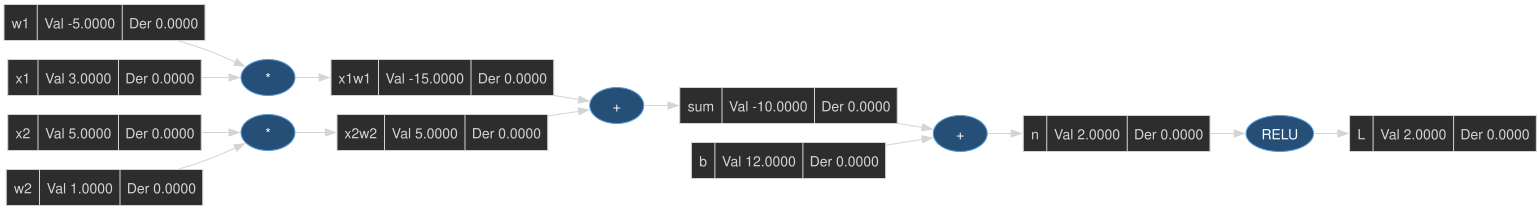

In [88]:
x1 = Scalar(3.0, 'x1')
w1 = Scalar(-5.0, 'w1')

x1w1 = x1 * w1 
x1w1.label = 'x1w1'

x2 = Scalar(5.0, 'x2')
w2 = Scalar(1.0, 'w2')

x2w2 = x2 * w2
x2w2.label = 'x2w2'

summation = x1w1 + x2w2
summation.label = 'sum'

b = Scalar(12.0, 'b')
b.label = 'b'

n = summation + b
n.label = 'n'

L = n.relu()
L.label = 'L'

draw_graph(L, rankdir='LR')

In [18]:
L.backward()

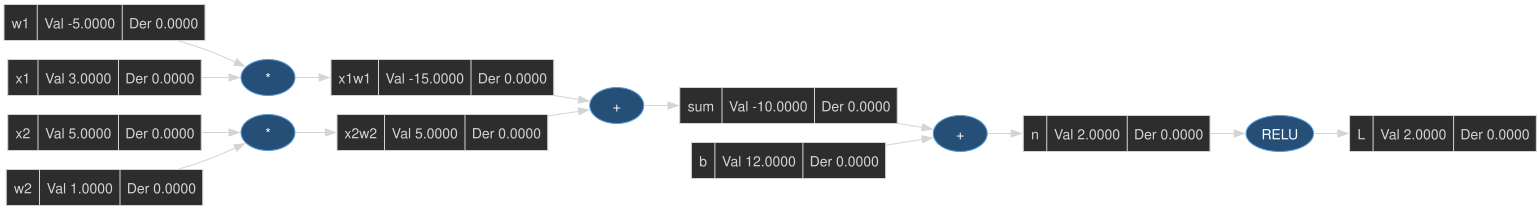

In [89]:
draw_graph(L, rankdir='LR')

In [20]:
x2.der

1.0

In [36]:
# torch objects I'll start with - praticing with torch
tx1 = torch.Tensor([3.0]).double(); tx1.requires_grad = True;
tw1 = torch.Tensor([-5.0]).double(); tw1.requires_grad = True; 

tx2 = torch.Tensor([5.0]).double(); tx2.requires_grad = True;
tw2 = torch.Tensor([1.0]).double(); tw2.requires_grad = True;

tb = torch.Tensor([12.0]).double(); tb.requires_grad = True;
tn = tx1 * tw1 + tx2 * tw2 + tb;

tn.retain_grad()
L = torch.relu(tn)
L.retain_grad()

In [37]:
print(L.data.item())

2.0


In [40]:
L.backward()
L.grad.item()

1.0

In [41]:
tx1.grad.item()

-5.0

In [90]:
class Neuron:
    def __init__(self, n_inputs, act='relu', initial_bias=None):
        self.weights = [Scalar(random.uniform(-1, 1), label=f'w{i + 1}') for i in range(n_inputs)]
        self.bias = Scalar(random.uniform(-1, 1), label='b') if initial_bias == None else initial_bias
        self.act = act
        self.last_pre = None

    def __call__(self, x): # x is basically the input array
        n = sum(xi * wi for xi, wi in zip(x, self.weights)) + self.bias
        if self.act == 'relu':
            return n.relu()
        return n # Linear

    @property
    def params(self):
        return self.weights + [self.bias]


In [62]:
n = Neuron(2)
x = [Scalar(1.0), Scalar(2.0)]
n(x)

In [64]:
print(n.params[0].label)
print(n.params[1].label)
print(n.params[2].label)

w1
w2
b


In [91]:
## Layer
class Layer:
    def __init__(self, n_inputs, n_outputs, **kwargs):
        self.neurons = [Neuron(n_inputs, **kwargs) for _ in range(n_outputs)]

    def __call__(self, x):
        outputs = [n(x) for n in self.neurons]
        return outputs[0] if len(outputs) == 1 else outputs

    @property
    def params(self):
        return [p for neuron in self.neurons for p in neuron.params]

        

In [92]:
## MLP
class MLP:
    '''
    Multi-Layer Perceptron
    '''
    def __init__(self, n_inputs, output_layers, act="relu", initial_bias=None): # n_inputs > is an number & output_layers is an array of numbers 
        sizes = [n_inputs] + output_layers
        self.layers = [
            Layer(
                sizes[i],
                sizes[i+1],
                act=act,
                initial_bias=initial_bias
            ) 
            for i in range(len(output_layers))
        ]

    def __call__(self, x): # TODO: this ain't that clear or ain't that intuitive to me!
        for l in self.layers:
            x = l(x)
        return x

    @property
    def params(self):
        return [p for l in self.layers for p in l.params]

In [93]:
nn = MLP(3, [4, 4, 1])

In [79]:
len(nn.params)

41

In [94]:
x_inp = [
    [3.0, 1.0, 1.0], # -> 1
    [4.0, 1.0, 1.0], # -> 3
    [2.0, 2.0, 1.0], # -> 0
    [5.0, 2.0, 1.0], # -> 2
    [1.0, 0.0, 2.0], # -> 0
]

y_exp = [1.0, 3.0, 0.0, 2.0, 0.0]

In [95]:
random.seed(2)
nn = MLP(3, [4,4,1]) 

In [96]:
y_pred = [nn(x) for x in x_inp] # predicted values

In [99]:
print([y.value for y in y_pred])

[0.9966774430645892, 1.7208070778534772, 0.9981722528074892, 3.1705611571741534, 0.7023229175018586]


In [101]:
loss = sum((ye - yp)**2 for ye, yp in zip(y_exp, y_pred))

In [102]:
loss

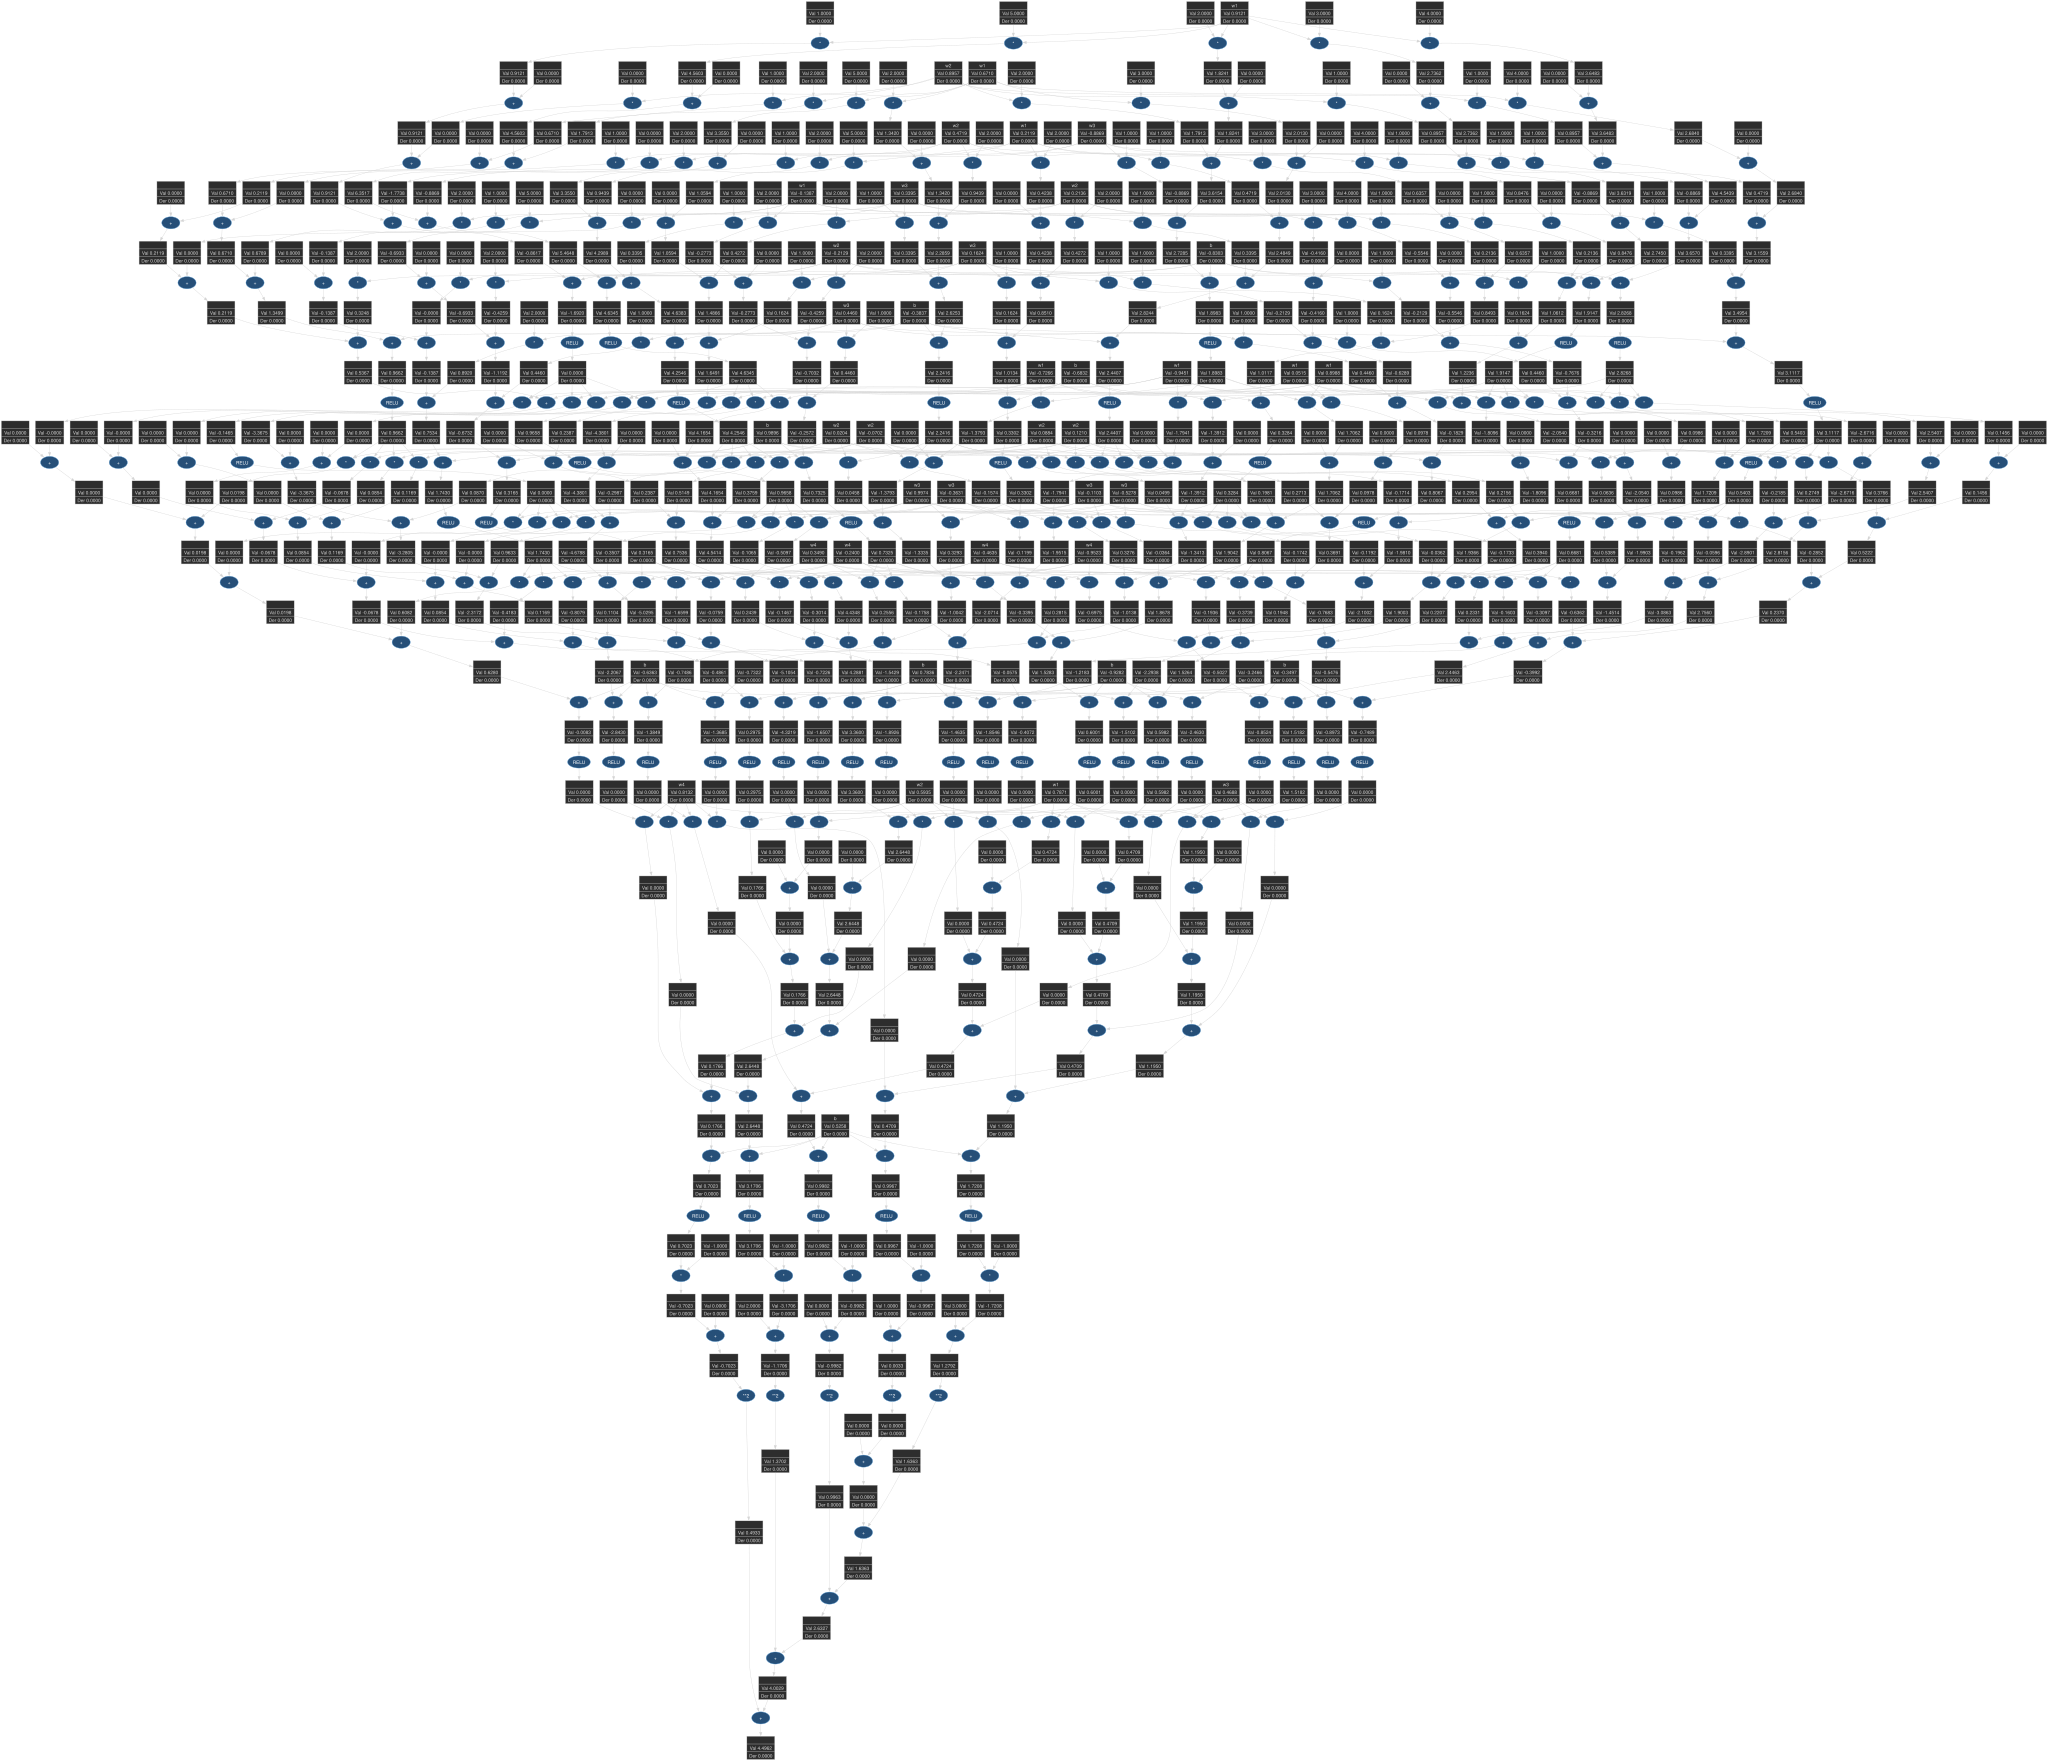

In [103]:
draw_graph(loss)

In [104]:
loss.backward()

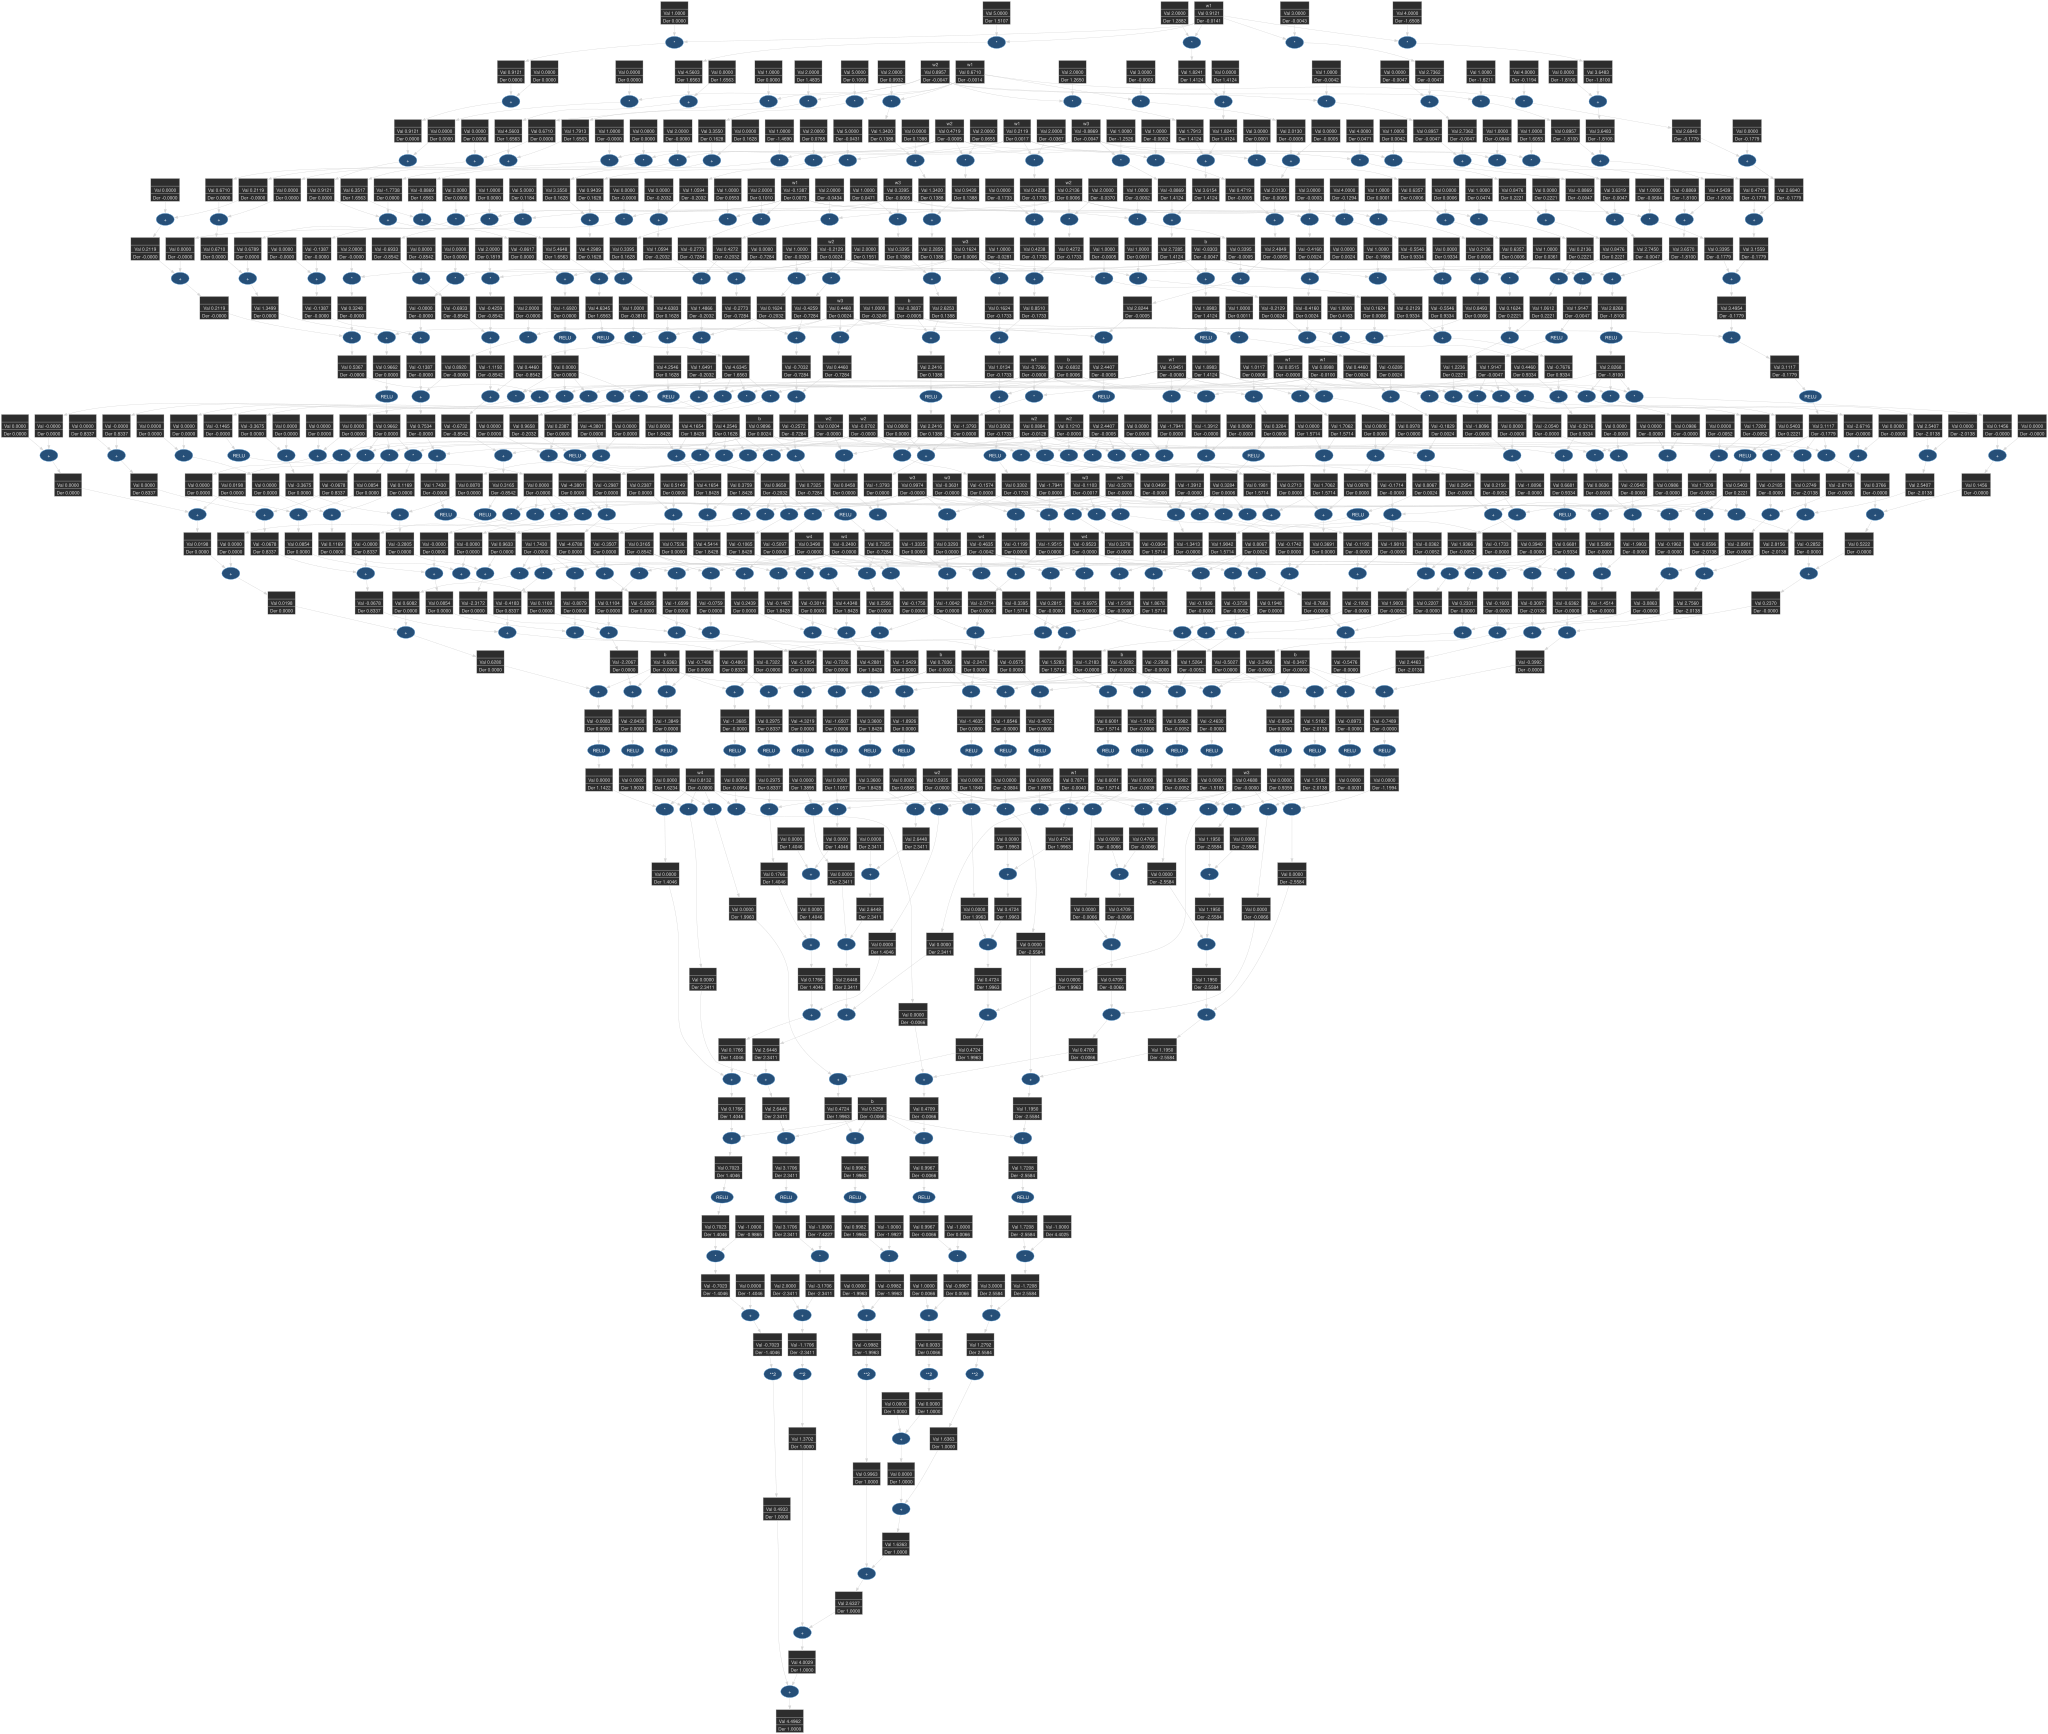

In [105]:
draw_graph(loss)